In [ ]:
from brian2 import *
from brian2tools import *
import matplotlib.pyplot as plt
import matplotlib.animation as animation
import numpy as np
import imageio
import os
from scipy.signal import convolve2d
from pathlib import Path
from progressbar import progressbar
from scipy.signal import butter, filtfilt, firwin


start_scope()

DATA_PATH = Path('data') 
TRAIN_IMG_PATH = DATA_PATH / 'train_images_diag'
defaultclock.dt = 100 * us

n_rc=10
n_input_rows = n_rc  
n_input_columns = n_rc 
n_output_rows = n_rc  
n_output_columns = n_rc 
N_inp = n_input_rows*n_input_columns
N_E = n_output_rows*n_output_columns
n_inh_rows, n_inh_cols = 5, 5
N_I = n_inh_rows * n_inh_cols

# Inhibitory neuron positions (scaled to excitatory grid)
inh_positions = []
for iy in range(n_inh_rows):
    for ix in range(n_inh_cols):
        # scale inhibitory coordinates to excitatory grid
        x = int((ix + 0.5) * n_output_columns / n_inh_cols)
        y = int((iy + 0.5) * n_output_rows / n_inh_rows)
        inh_positions.append((x, y))


# voltage
V_L = -70. * mV
V_thr = -50. * mV
V_reset = -60. * mV
V_E = 0.0 * mV
V_I = -70. * mV

# membrane capacitance
C_m_E = 0.5 * nF
C_m_I = 0.1 * nF

# membrane leak
g_m_E = 10. * nS
g_m_I = 3. * nS

# refractory period
tau_rp_E = 2. * ms
tau_rp_I = 1. * ms

# AMPA
g_AMPA_ext_E = 5.7 * nS 
g_AMPA_rec_E = 5.7 * nS 
g_AMPA_ext_I = 5.7 * nS
g_AMPA_rec_I = 5.7 * nS 
tau_AMPA = 8. * ms


# GABAa
g_GABA_E = 1.0*nS 
g_GABA_I = 1.0*nS 
tau_GABA = 10. * ms



#STDP/iSTDP
Apre   =  0.0025
Apost  = -0.0030
w_max = 1.0 #1.5

Apre_i  = -0.0010
Apost_i =  0.0012
w_max_i = 1.0


tau_HSP = 100*second           
target_rate = 2.0*Hz            
record_dt = 200*ms

tau_vm = 10*second
tau_active = 10*second
  

center_neurons = [14, 24,34, 44, 54, 64,89]
recurrent_radius = 3


kill_mask = np.ones(100, dtype=np.float32)
#kill_mask[range(40,47)]=0 #yes
#kill_mask[np.array([range(40,47),range(21,28)]).flatten()]=0 #yes
kill_mask[np.array([range(42,47),range(32,37)]).flatten()]=0



def load_npy(path):
    arr = np.load(path)
    print('Loading', path, arr.shape)
    return arr

def save_npy(arr, path):
    arr = np.array(arr)
    print('Saving', arr.shape, path)
    np.save(path, arr)


def build_network():
    # variables
    n_input_rows = 10  
    n_input_columns = 10 
    n_output_rows = 10 
    n_output_columns = 10 
    N_inp = n_input_rows*n_input_columns
    N_E = n_output_rows*n_output_columns
    n_inh_rows, n_inh_cols = 5, 5
    N_I = n_inh_rows * n_inh_cols 

    # modeling
    eqs_E = '''
    dv / dt = (- g_m_E * (v - V_L) - I_syn ) / C_m_E : volt (unless refractory)
    I_syn = I_AMPA_ext + I_AMPA_rec + I_GABA_rec : amp

    # Homeostatically scaled synaptic currents
    I_AMPA_ext = g_AMPA_ext_E  * (v - V_E) * s_AMPA_ext : amp
    I_AMPA_rec = g_AMPA_rec_E * k_AMPA_E_hsp  * (v - V_E) * s_AMPA : amp
    I_GABA_rec = g_GABA_E * k_GABA_E_hsp * (v - V_I) * s_GABA     : amp

    ds_AMPA_ext / dt = - s_AMPA_ext / tau_AMPA : 1
    ds_AMPA / dt      = - s_AMPA / tau_AMPA     : 1
    ds_GABA / dt      = - s_GABA / tau_GABA     : 1

    dx_spike / dt = -x_spike/tau_HSP : 1
    r_est = x_spike / tau_HSP : Hz

    # HSP scaling variables (dimensionless)
    dk_AMPA_E_hsp/dt = ((1 - k_AMPA_E_hsp) * 1/(1+exp(-15*((target_rate - r_est)/target_rate-0.5))) / tau_ins_AMPA_E
                - (k_AMPA_E_hsp - 0.1) * 1/(1+exp(-15*((r_est - target_rate)/target_rate-0.5))) / tau_int_AMPA_E) : 1

    dk_GABA_E_hsp/dt = (-(k_GABA_E_hsp - 0.1) * 1/(1+exp(-15*((target_rate - r_est)/target_rate-0.5))) / tau_int_GABA_E
                + (1 - k_GABA_E_hsp) * 1/(1+exp(-15*((r_est - target_rate)/target_rate-0.5))) / tau_ins_GABA_E) : 1

    dvm_lp / dt = (v - vm_lp)/tau_vm : volt
    dy_act / dt = -y_act / tau_active : 1

    tau_ins_AMPA_E : second (shared)
    tau_int_AMPA_E : second (shared)
    tau_int_GABA_E : second (shared)
    tau_ins_GABA_E : second (shared)
    '''


    eqs_I = '''
    dv / dt = (- g_m_I * (v - V_L) - I_syn) / C_m_I : volt (unless refractory)
    I_syn = I_AMPA_ext + I_AMPA_rec + I_GABA_rec : amp
    I_AMPA_ext = g_AMPA_ext_I * (v - V_E) * s_AMPA_ext : amp
    I_AMPA_rec = g_AMPA_rec_I * 0.3 * (v - V_E) * 1 * s_AMPA : amp
    ds_AMPA_ext / dt = - s_AMPA_ext / tau_AMPA : 1
    ds_AMPA / dt = - s_AMPA / tau_AMPA : 1

    I_GABA_rec = g_GABA_I * 0.3 * (v - V_I) * s_GABA : amp
    ds_GABA / dt = - s_GABA / tau_GABA : 1

    dx_spike / dt = -x_spike/tau_HSP : 1
    r_est = x_spike / tau_HSP : Hz


    dy_act / dt = -y_act / tau_active : 1
    '''


    P_E = NeuronGroup(N_E, eqs_E, threshold='v > V_thr', reset='v = V_reset; x_spike += 1.; y_act=1.', refractory=tau_rp_E, method='euler')
    P_E.v = V_L
    P_E.k_AMPA_E_hsp = 0.3  
    P_E.k_GABA_E_hsp = 0.3  
    P_E.tau_ins_AMPA_E = 500*second   #50'000
    P_E.tau_int_AMPA_E = 500*second    #5'000
    P_E.tau_ins_GABA_E = 500*second   
    P_E.tau_int_GABA_E = 500*second   

    P_I = NeuronGroup(N_I, eqs_I, threshold='v > V_thr', reset='v = V_reset; x_spike += 1.; y_act=1.', refractory=tau_rp_I, method='euler')
    P_I.v = V_L


    pg_inp = PoissonGroup(N_inp, rates=0 * Hz, name = 'inp')

    
    C_PG_E = Synapses(pg_inp, P_E, model='w:1', on_pre = '''
        s_AMPA_ext += w  
        ''', method='euler', name='PG_E')
    C_PG_E.connect(j='i')  

    
    C_E_E  = Synapses(P_E, P_E, model='w:1', on_pre = '''
        s_AMPA += w  
        ''', method='euler', name='E_E')
    recurrent_radius = 2
    for y1 in range(n_output_rows):
        for x1 in range(n_output_columns):
            post = y1 * n_output_columns + x1
            for dy in range(-recurrent_radius, recurrent_radius + 1):
                for dx in range(-recurrent_radius, recurrent_radius + 1):
                    if dx == 0 and dy == 0:
                        continue
                    x2 = x1 + dx
                    y2 = y1 + dy
                    if 0 <= x2 < n_output_columns and 0 <= y2 < n_output_rows:
                        pre = y2 * n_output_columns + x2
                        C_E_E.connect(i=pre, j=post)
    C_E_I  = Synapses(P_E, P_I, model='w:1', on_pre='''
    s_AMPA += w
    ''', method='euler', name='E_I') #        x_postE_post += 1.0 
    C_I_E  = Synapses(P_I, P_E, model='w:1', on_pre='s_GABA += w', method='euler', name='I_E')
    for inh_idx, (ix, iy) in enumerate(inh_positions):
        for ex_y in range(n_output_rows):
            for ex_x in range(n_output_columns):
                if abs(ex_x - ix) <= recurrent_radius and abs(ex_y - iy) <= recurrent_radius:
                    exc_idx = ex_y * n_output_columns + ex_x
                    C_I_E.connect(i=inh_idx, j=exc_idx)
                    C_E_I.connect(i=exc_idx, j=inh_idx)
    C_I_I  = Synapses(P_I, P_I, model='w:1', on_pre='s_GABA += w', method='euler', name='I_I')
    for iy in range(n_inh_rows):
        for ix in range(n_inh_cols):
            post = iy * n_inh_cols + ix
            for dy in range(-1, 2):
                for dx in range(-1, 2):
                    if dx == 0 and dy == 0:
                        continue
                    x2, y2 = ix + dx, iy + dy
                    if 0 <= x2 < n_inh_cols and 0 <= y2 < n_inh_rows:
                        pre = y2 * n_inh_cols + x2
                        C_I_I.connect(i=pre, j=post)



    C_PG_E.w[:] = 1.2 #np.clip(np.random.normal(loc=0.20, scale=0.05, size=len(C_PG_E.w)), 0.0, 1.0)#w_PG_E
    C_I_E.w[:] = np.clip(np.random.normal(loc=0.30, scale=0.05, size=len(C_I_E.w)), 0.0, 1.0)#w_I_E
    C_I_I.w[:] = np.clip(np.random.normal(loc=0.30, scale=0.05, size=len(C_I_I.w)), 0.0, 1.0)#w_I_I
    C_E_I.w[:] = 0.6#np.clip(np.random.normal(loc=0.40, scale=0.05, size=len(C_E_I.w)), 0.0, 1.0)#w_E_I
    C_E_E.w[:] = np.clip(np.random.normal(loc=0.44, scale=0.05, size=len(C_E_E.w)), 0.0, 1.0)#w_E_E


    vm_container = NeuronGroup(1, 'vm_pop : volt', method='euler')
    C_vm = Synapses(P_E, vm_container,
                model='vm_pop_post = vm_lp_pre / N_pre : volt (summed)', 
                method='euler')
    C_vm.connect()

    act_container = NeuronGroup(1, 'frac_act : 1', method='euler')
    
    C_act = Synapses(
        P_E, act_container,
        model='''scale:1 (constant)
            frac_act_post = scale * clip(y_act_pre, 0, 1) : 1 (summed)''',
        method='euler'
    )
    C_act.connect()
    C_act.scale = 1.0/float(N_E)

    act_cont_I = NeuronGroup(1, 'frac_act : 1', method='euler')
    
    C_act_I = Synapses(
        P_I, act_cont_I,
        model='''scale:1 (constant)
            frac_act_post = scale * clip(y_act_pre, 0, 1) : 1 (summed)''',
        method='euler'
    )
    C_act_I.connect()
    C_act_I.scale = 1.0/float(N_I)
    
    rate_container_E = NeuronGroup(1, 'r_pop_E : Hz', method='euler')
    C_rE = Synapses(P_E, rate_container_E,
                model='r_pop_E_post = r_est_pre / N_pre : Hz (summed)',
                method='euler')
    C_rE.connect()

    rate_container_I = NeuronGroup(1, 'r_pop_I : Hz', method='euler')
    C_rI = Synapses(P_I, rate_container_I,
                model='r_pop_I_post = r_est_pre / N_pre : Hz (summed)',
                method='euler')
    C_rI.connect()

    # monitors
    V_mon = StateMonitor(vm_container, 'vm_pop', record=True, dt=record_dt,name='V_mon')
    act_mon = StateMonitor(act_container, 'frac_act', record=True, dt=record_dt, name='act_mon')
    act_mon_I = StateMonitor(act_cont_I, 'frac_act', record=True, dt=record_dt, name='act_mon_I')
    
    rate_pop_mon_E = StateMonitor(rate_container_E, 'r_pop_E', record=True, dt=record_dt, name='rate_pop_mon_E')
    rate_pop_mon_I = StateMonitor(rate_container_I, 'r_pop_I', record=True, dt=record_dt, name='rate_pop_mon_I')

    gAMPA_mon_E = StateMonitor(P_E, 'k_AMPA_E_hsp', record=True, dt=record_dt, name='k_AMPA_E_hsp')
    gGABA_mon_E = StateMonitor(P_E, 'k_GABA_E_hsp', record=True, dt=record_dt, name='k_GABA_E_hsp')

    sp_E = SpikeMonitor(P_E, name = 'sp_exc')
    sp_I = SpikeMonitor(P_I, name = 'sp_inh')


    net = Network(collect())
    net.run(0*ms, report='stdout') # 
    return net



def show_rand_rate(net, show_time = 1000*ms):
    N_inp=net['inp'].N
    rates = np.random.normal(loc=40, scale=3, size=N_inp)
    rates *= kill_mask
    rate_img = np.clip(rates, 5, 50)*Hz
    net['inp'].rates = rate_img
    net.run(show_time, report = 'text')



def run_sim(show_time = 1000*ms):
    net = build_network()
    show_rand_rate(show_time=show_time)
    return net



INFO       Cache size for target 'cython': 2090 MB.
You can call clear_cache('cython') to delete all files from the cache or manually delete files in the '/home/vincent/.cython/brian_extensions' directory. [brian2]


INFO:root:creating /tmp/brian_flag_test_pri9jatn/tmp
INFO:root:creating /tmp/brian_flag_test_pri9jatn/tmp/brian_flag_test_pri9jatn
INFO:root:x86_64-linux-gnu-gcc -fno-strict-overflow -Wsign-compare -DNDEBUG -g -O2 -Wall -fPIC -c /tmp/brian_flag_test_pri9jatn/flag_test.cpp -o /tmp/brian_flag_test_pri9jatn/tmp/brian_flag_test_pri9jatn/flag_test.o -w
INFO:root:creating /tmp/brian_flag_test_vas79s5s/tmp
INFO:root:creating /tmp/brian_flag_test_vas79s5s/tmp/brian_flag_test_vas79s5s
INFO:root:x86_64-linux-gnu-gcc -fno-strict-overflow -Wsign-compare -DNDEBUG -g -O2 -Wall -fPIC -c /tmp/brian_flag_test_vas79s5s/flag_test.cpp -o /tmp/brian_flag_test_vas79s5s/tmp/brian_flag_test_vas79s5s/flag_test.o -O3
INFO:root:creating /tmp/brian_flag_test_fta763g0/tmp
INFO:root:creating /tmp/brian_flag_test_fta763g0/tmp/brian_flag_test_fta763g0
INFO:root:x86_64-linux-gnu-gcc -fno-strict-overflow -Wsign-compare -DNDEBUG -g -O2 -Wall -fPIC -c /tmp/brian_flag_test_fta763g0/flag_test.cpp -o /tmp/brian_flag_test_ft

Starting simulation at t=0. s for a duration of 0. s
0. s (100%) simulated in < 1s


WARNING    'rates' is an internal variable of group 'inp', but also exists in the run namespace with the value array([39.64488102, 41.8887346 , 40.54164304, ..., 38.85404173,
       39.99695025, 30.81447196]). The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]


Starting simulation at t=0. s for a duration of 10. ks
139.317 s (1%) simulated in 10s, estimated 11m 48s remaining.
298.499 s (2%) simulated in 20s, estimated 10m 50s remaining.
0.467002 ks (4%) simulated in 30s, estimated 10m 12s remaining.
0.617223 ks (6%) simulated in 40s, estimated 10m 8s remaining.
0.75467 ks (7%) simulated in 50s, estimated 10m 13s remaining.
0.912745 ks (9%) simulated in 1m 0s, estimated 9m 57s remaining.
1.071406 ks (10%) simulated in 1m 10s, estimated 9m 43s remaining.
1.206249 ks (12%) simulated in 1m 20s, estimated 9m 43s remaining.
1.351898 ks (13%) simulated in 1m 30s, estimated 9m 36s remaining.
1.502647 ks (15%) simulated in 1m 40s, estimated 9m 25s remaining.
1.643171 ks (16%) simulated in 1m 50s, estimated 9m 19s remaining.
1.798994 ks (17%) simulated in 2m 0s, estimated 9m 7s remaining.
1.950957 ks (19%) simulated in 2m 10s, estimated 8m 56s remaining.
2.105307 ks (21%) simulated in 2m 20s, estimated 8m 45s remaining.
2.24754 ks (22%) simulated in 2m

WARNING    /home/vincent/bmnn/lib/python3.12/site-packages/brian2tools/plotting/data.py:59: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "." (-> marker='.'). The keyword argument will take precedence.
  axes.plot(spike_times/time_unit, spike_indices, '.', **kwds)
 [py.warnings]
  axes.plot(spike_times/time_unit, spike_indices, '.', **kwds)



Tested image 1/1


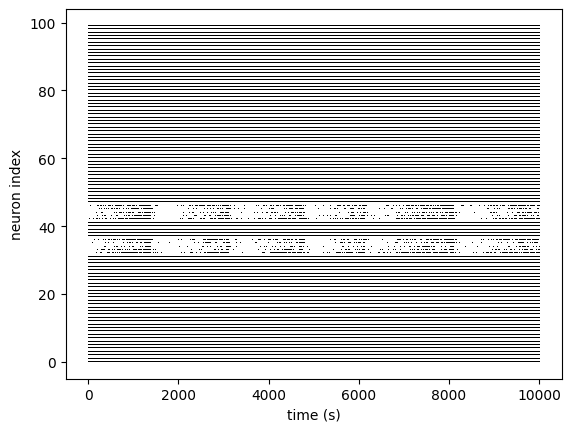

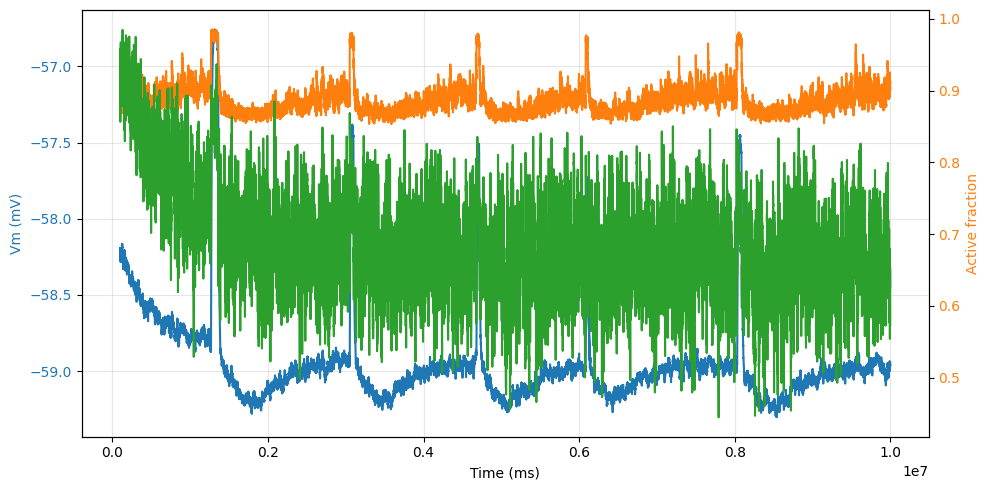

In [2]:
start_scope()
defaultclock.dt = 1000 * us
net = run_sim(show_time=10000*second)


V_mon = net['V_mon']  
act_mon=net['act_mon']
act_mon_I=net['act_mon_I']
spE = net['sp_exc']
spI = net['sp_inh']
plot_raster(spE.i, spE.t, time_unit=second, marker=',', color='k')


fig, ax1 = plt.subplots(figsize=(10,5))

ax1.plot(V_mon.t[500:]/ms, V_mon.vm_pop[0,500:]/mV, color='tab:blue', label='Vm mean')
ax1.set_xlabel('Time (ms)')
ax1.set_ylabel('Vm (mV)', color='tab:blue')
ax1.tick_params(axis='y', labelcolor='tab:blue')
ax1.grid(True, alpha=0.3)

ax2 = ax1.twinx()
ax2.plot(act_mon.t[500:]/ms, act_mon.frac_act[0,500:], color='tab:orange', label='Active fraction')
ax2.plot(act_mon_I.t[500:]/ms, act_mon_I.frac_act[0,500:], color='tab:green', label='Active fraction')
ax2.set_ylabel('Active fraction', color='tab:orange')
ax2.tick_params(axis='y', labelcolor='tab:orange')

fig.tight_layout()
plt.show()

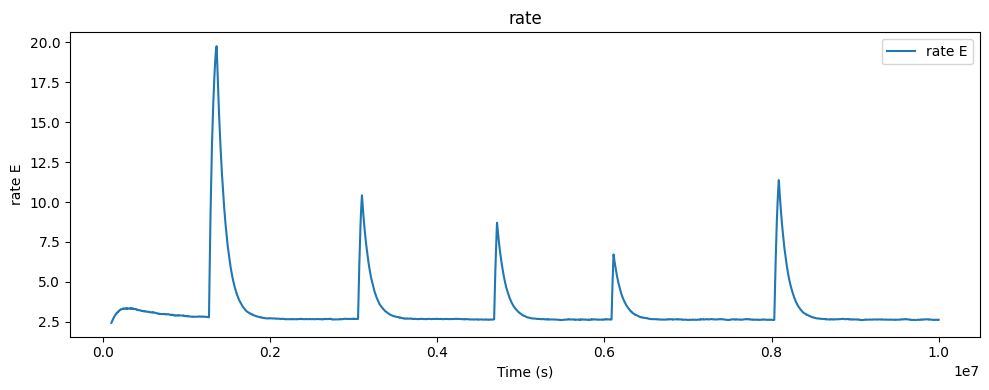

In [4]:
r_est_E = net['rate_pop_mon_E']  
r_est_I = net['rate_pop_mon_I']  

plt.figure(figsize=(10, 4))
plt.plot(r_est_E.t[500:]/ms, r_est_E.r_pop_E[0,500:]/Hz, color='tab:blue', label='rate E')
#plt.plot(r_est_I.t[500:]/ms, r_est_I.r_pop_I[0,500:]/Hz, color='tab:green', label='rate I')
plt.xlabel('Time (s)')
plt.ylabel('rate E')
plt.title('rate')
plt.legend()
plt.tight_layout()

<Axes: xlabel='time (s)', ylabel='neuron index'>

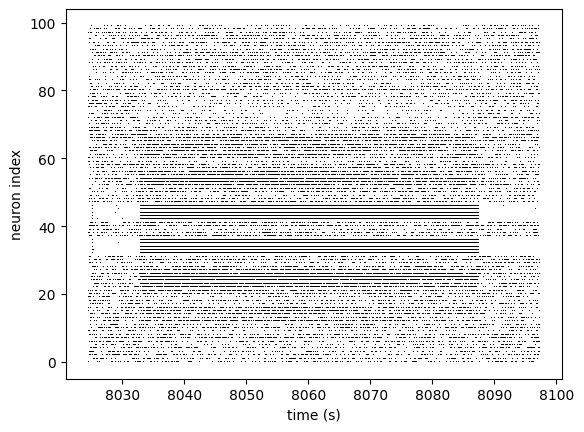

In [12]:
plot_raster(spE.i[int(2.685*10**6):int(2.82*10**6)], spE.t[int(2.685*10**6):int(2.82*10**6)], time_unit=second, marker=',', color='k')

Longer TC for longer period of high risk

In [15]:
from brian2 import *
from brian2tools import *
import matplotlib.pyplot as plt
import matplotlib.animation as animation
import numpy as np
import imageio
import os
from scipy.signal import convolve2d
from pathlib import Path
from progressbar import progressbar
from scipy.signal import butter, filtfilt, firwin


start_scope()

DATA_PATH = Path('data') 
TRAIN_IMG_PATH = DATA_PATH / 'train_images_diag'
defaultclock.dt = 100 * us

n_rc=10
n_input_rows = n_rc  
n_input_columns = n_rc 
n_output_rows = n_rc  
n_output_columns = n_rc 
N_inp = n_input_rows*n_input_columns
N_E = n_output_rows*n_output_columns
n_inh_rows, n_inh_cols = 5, 5
N_I = n_inh_rows * n_inh_cols

# Inhibitory neuron positions (scaled to excitatory grid)
inh_positions = []
for iy in range(n_inh_rows):
    for ix in range(n_inh_cols):
        # scale inhibitory coordinates to excitatory grid
        x = int((ix + 0.5) * n_output_columns / n_inh_cols)
        y = int((iy + 0.5) * n_output_rows / n_inh_rows)
        inh_positions.append((x, y))


# voltage
V_L = -70. * mV
V_thr = -50. * mV
V_reset = -60. * mV
V_E = 0.0 * mV
V_I = -70. * mV

# membrane capacitance
C_m_E = 0.5 * nF
C_m_I = 0.1 * nF

# membrane leak
g_m_E = 10. * nS
g_m_I = 3. * nS

# refractory period
tau_rp_E = 2. * ms
tau_rp_I = 1. * ms

# AMPA
g_AMPA_ext_E = 5.7 * nS 
g_AMPA_rec_E = 5.7 * nS 
g_AMPA_ext_I = 5.7 * nS
g_AMPA_rec_I = 5.7 * nS 
tau_AMPA = 8. * ms


# GABAa
g_GABA_E = 1.0*nS 
g_GABA_I = 1.0*nS 
tau_GABA = 10. * ms



#STDP/iSTDP
Apre   =  0.0025
Apost  = -0.0030
w_max = 1.0 #1.5

Apre_i  = -0.0010
Apost_i =  0.0012
w_max_i = 1.0


tau_HSP = 100*second           
target_rate = 2.0*Hz            
record_dt = 200*ms

tau_vm = 10*second
tau_active = 10*second
  

center_neurons = [14, 24,34, 44, 54, 64,89]
recurrent_radius = 3


kill_mask = np.ones(100, dtype=np.float32)
#kill_mask[range(40,47)]=0 #yes
#kill_mask[np.array([range(40,47),range(21,28)]).flatten()]=0 #yes
kill_mask[np.array([range(42,47),range(32,37)]).flatten()]=0



def load_npy(path):
    arr = np.load(path)
    print('Loading', path, arr.shape)
    return arr

def save_npy(arr, path):
    arr = np.array(arr)
    print('Saving', arr.shape, path)
    np.save(path, arr)


def build_network(tau_ins_AMPA,tau_int_AMPA,tau_ins_GABA,tau_int_GABA):
    # variables
    n_input_rows = 10  
    n_input_columns = 10 
    n_output_rows = 10 
    n_output_columns = 10 
    N_inp = n_input_rows*n_input_columns
    N_E = n_output_rows*n_output_columns
    n_inh_rows, n_inh_cols = 5, 5
    N_I = n_inh_rows * n_inh_cols 

    # modeling
    eqs_E = '''
    dv / dt = (- g_m_E * (v - V_L) - I_syn ) / C_m_E : volt (unless refractory)
    I_syn = I_AMPA_ext + I_AMPA_rec + I_GABA_rec : amp

    # Homeostatically scaled synaptic currents
    I_AMPA_ext = g_AMPA_ext_E  * (v - V_E) * s_AMPA_ext : amp
    I_AMPA_rec = g_AMPA_rec_E * k_AMPA_E_hsp  * (v - V_E) * s_AMPA : amp
    I_GABA_rec = g_GABA_E * k_GABA_E_hsp * (v - V_I) * s_GABA     : amp

    ds_AMPA_ext / dt = - s_AMPA_ext / tau_AMPA : 1
    ds_AMPA / dt      = - s_AMPA / tau_AMPA     : 1
    ds_GABA / dt      = - s_GABA / tau_GABA     : 1

    dx_spike / dt = -x_spike/tau_HSP : 1
    r_est = x_spike / tau_HSP : Hz

    # HSP scaling variables (dimensionless)
    dk_AMPA_E_hsp/dt = ((1 - k_AMPA_E_hsp) * 1/(1+exp(-15*((target_rate - r_est)/target_rate-0.5))) / tau_ins_AMPA_E
                - (k_AMPA_E_hsp - 0.1) * 1/(1+exp(-15*((r_est - target_rate)/target_rate-0.5))) / tau_int_AMPA_E) : 1

    dk_GABA_E_hsp/dt = (-(k_GABA_E_hsp - 0.1) * 1/(1+exp(-15*((target_rate - r_est)/target_rate-0.5))) / tau_int_GABA_E
                + (1 - k_GABA_E_hsp) * 1/(1+exp(-15*((r_est - target_rate)/target_rate-0.5))) / tau_ins_GABA_E) : 1

    dvm_lp / dt = (v - vm_lp)/tau_vm : volt
    dy_act / dt = -y_act / tau_active : 1

    tau_ins_AMPA_E : second (shared)
    tau_int_AMPA_E : second (shared)
    tau_int_GABA_E : second (shared)
    tau_ins_GABA_E : second (shared)
    '''


    eqs_I = '''
    dv / dt = (- g_m_I * (v - V_L) - I_syn) / C_m_I : volt (unless refractory)
    I_syn = I_AMPA_ext + I_AMPA_rec + I_GABA_rec : amp
    I_AMPA_ext = g_AMPA_ext_I * (v - V_E) * s_AMPA_ext : amp
    I_AMPA_rec = g_AMPA_rec_I * 0.3 * (v - V_E) * 1 * s_AMPA : amp
    ds_AMPA_ext / dt = - s_AMPA_ext / tau_AMPA : 1
    ds_AMPA / dt = - s_AMPA / tau_AMPA : 1

    I_GABA_rec = g_GABA_I * 0.3 * (v - V_I) * s_GABA : amp
    ds_GABA / dt = - s_GABA / tau_GABA : 1

    dx_spike / dt = -x_spike/tau_HSP : 1
    r_est = x_spike / tau_HSP : Hz


    dy_act / dt = -y_act / tau_active : 1
    '''


    P_E = NeuronGroup(N_E, eqs_E, threshold='v > V_thr', reset='v = V_reset; x_spike += 1.; y_act=1.', refractory=tau_rp_E, method='euler')
    P_E.v = V_L
    P_E.k_AMPA_E_hsp = 0.3  
    P_E.k_GABA_E_hsp = 0.3  
    P_E.tau_ins_AMPA_E = tau_ins_AMPA   #50'000
    P_E.tau_int_AMPA_E = tau_int_AMPA   #5'000
    P_E.tau_ins_GABA_E = tau_ins_GABA   
    P_E.tau_int_GABA_E = tau_int_GABA  

    P_I = NeuronGroup(N_I, eqs_I, threshold='v > V_thr', reset='v = V_reset; x_spike += 1.; y_act=1.', refractory=tau_rp_I, method='euler')
    P_I.v = V_L


    pg_inp = PoissonGroup(N_inp, rates=0 * Hz, name = 'inp')

    
    C_PG_E = Synapses(pg_inp, P_E, model='w:1', on_pre = '''
        s_AMPA_ext += w  
        ''', method='euler', name='PG_E')
    C_PG_E.connect(j='i')  

    
    C_E_E  = Synapses(P_E, P_E, model='w:1', on_pre = '''
        s_AMPA += w  
        ''', method='euler', name='E_E')
    recurrent_radius = 2
    for y1 in range(n_output_rows):
        for x1 in range(n_output_columns):
            post = y1 * n_output_columns + x1
            for dy in range(-recurrent_radius, recurrent_radius + 1):
                for dx in range(-recurrent_radius, recurrent_radius + 1):
                    if dx == 0 and dy == 0:
                        continue
                    x2 = x1 + dx
                    y2 = y1 + dy
                    if 0 <= x2 < n_output_columns and 0 <= y2 < n_output_rows:
                        pre = y2 * n_output_columns + x2
                        C_E_E.connect(i=pre, j=post)
    C_E_I  = Synapses(P_E, P_I, model='w:1', on_pre='''
    s_AMPA += w
    ''', method='euler', name='E_I') #        x_postE_post += 1.0 
    C_I_E  = Synapses(P_I, P_E, model='w:1', on_pre='s_GABA += w', method='euler', name='I_E')
    for inh_idx, (ix, iy) in enumerate(inh_positions):
        for ex_y in range(n_output_rows):
            for ex_x in range(n_output_columns):
                if abs(ex_x - ix) <= recurrent_radius and abs(ex_y - iy) <= recurrent_radius:
                    exc_idx = ex_y * n_output_columns + ex_x
                    C_I_E.connect(i=inh_idx, j=exc_idx)
                    C_E_I.connect(i=exc_idx, j=inh_idx)
    C_I_I  = Synapses(P_I, P_I, model='w:1', on_pre='s_GABA += w', method='euler', name='I_I')
    for iy in range(n_inh_rows):
        for ix in range(n_inh_cols):
            post = iy * n_inh_cols + ix
            for dy in range(-1, 2):
                for dx in range(-1, 2):
                    if dx == 0 and dy == 0:
                        continue
                    x2, y2 = ix + dx, iy + dy
                    if 0 <= x2 < n_inh_cols and 0 <= y2 < n_inh_rows:
                        pre = y2 * n_inh_cols + x2
                        C_I_I.connect(i=pre, j=post)



    C_PG_E.w[:] = 1.2 #np.clip(np.random.normal(loc=0.20, scale=0.05, size=len(C_PG_E.w)), 0.0, 1.0)#w_PG_E
    C_I_E.w[:] = np.clip(np.random.normal(loc=0.30, scale=0.05, size=len(C_I_E.w)), 0.0, 1.0)#w_I_E
    C_I_I.w[:] = np.clip(np.random.normal(loc=0.30, scale=0.05, size=len(C_I_I.w)), 0.0, 1.0)#w_I_I
    C_E_I.w[:] = 0.6#np.clip(np.random.normal(loc=0.40, scale=0.05, size=len(C_E_I.w)), 0.0, 1.0)#w_E_I
    C_E_E.w[:] = np.clip(np.random.normal(loc=0.44, scale=0.05, size=len(C_E_E.w)), 0.0, 1.0)#w_E_E


    vm_container = NeuronGroup(1, 'vm_pop : volt', method='euler')
    C_vm = Synapses(P_E, vm_container,
                model='vm_pop_post = vm_lp_pre / N_pre : volt (summed)', 
                method='euler')
    C_vm.connect()

    act_container = NeuronGroup(1, 'frac_act : 1', method='euler')
    
    C_act = Synapses(
        P_E, act_container,
        model='''scale:1 (constant)
            frac_act_post = scale * clip(y_act_pre, 0, 1) : 1 (summed)''',
        method='euler'
    )
    C_act.connect()
    C_act.scale = 1.0/float(N_E)

    act_cont_I = NeuronGroup(1, 'frac_act : 1', method='euler')
    
    C_act_I = Synapses(
        P_I, act_cont_I,
        model='''scale:1 (constant)
            frac_act_post = scale * clip(y_act_pre, 0, 1) : 1 (summed)''',
        method='euler'
    )
    C_act_I.connect()
    C_act_I.scale = 1.0/float(N_I)
    
    rate_container_E = NeuronGroup(1, 'r_pop_E : Hz', method='euler')
    C_rE = Synapses(P_E, rate_container_E,
                model='r_pop_E_post = r_est_pre / N_pre : Hz (summed)',
                method='euler')
    C_rE.connect()

    rate_container_I = NeuronGroup(1, 'r_pop_I : Hz', method='euler')
    C_rI = Synapses(P_I, rate_container_I,
                model='r_pop_I_post = r_est_pre / N_pre : Hz (summed)',
                method='euler')
    C_rI.connect()

    # monitors
    V_mon = StateMonitor(vm_container, 'vm_pop', record=True, dt=record_dt,name='V_mon')
    act_mon = StateMonitor(act_container, 'frac_act', record=True, dt=record_dt, name='act_mon')
    act_mon_I = StateMonitor(act_cont_I, 'frac_act', record=True, dt=record_dt, name='act_mon_I')
    
    rate_pop_mon_E = StateMonitor(rate_container_E, 'r_pop_E', record=True, dt=record_dt, name='rate_pop_mon_E')
    rate_pop_mon_I = StateMonitor(rate_container_I, 'r_pop_I', record=True, dt=record_dt, name='rate_pop_mon_I')

    gAMPA_mon_E = StateMonitor(P_E, 'k_AMPA_E_hsp', record=True, dt=record_dt, name='k_AMPA_E_hsp')
    gGABA_mon_E = StateMonitor(P_E, 'k_GABA_E_hsp', record=True, dt=record_dt, name='k_GABA_E_hsp')

    sp_E = SpikeMonitor(P_E, name = 'sp_exc')
    sp_I = SpikeMonitor(P_I, name = 'sp_inh')


    net = Network(collect())
    net.run(0*ms, report='stdout') # 
    return net



def show_rand_rate(net, show_time = 1000*ms):
    N_inp=net['inp'].N
    rates = np.random.normal(loc=40, scale=3, size=N_inp)
    rates *= kill_mask
    rate_img = np.clip(rates, 5, 50)*Hz
    net['inp'].rates = rate_img
    net.run(show_time, report = 'text')



def run_sim(tau_ins_AMPA,tau_int_AMPA,tau_ins_GABA,tau_int_GABA,show_time = 1000*ms):
    net = build_network(tau_ins_AMPA=tau_ins_AMPA,tau_int_AMPA=tau_int_AMPA,tau_ins_GABA=tau_ins_GABA,tau_int_GABA=tau_int_GABA)
    show_rand_rate(net,show_time=show_time)
    return net



INFO:root:building '_cython_magic_356bfe3003237d1fea3a8b71da4e8fae' extension
INFO:root:x86_64-linux-gnu-gcc -fno-strict-overflow -Wsign-compare -DNDEBUG -g -O2 -Wall -fPIC -I/home/vincent/bmnn/include -I/home/vincent/bmnn/lib/python3.12/site-packages/numpy/core/include -I/home/vincent/bmnn/lib/python3.12/site-packages/brian2/synapses -I/home/vincent/bmnn/include -I/usr/include/python3.12 -c /home/vincent/.cython/brian_extensions/_cython_magic_356bfe3003237d1fea3a8b71da4e8fae.cpp -o /home/vincent/.cython/brian_extensions/home/vincent/.cython/brian_extensions/_cython_magic_356bfe3003237d1fea3a8b71da4e8fae.o -w -O3 -ffast-math -fno-finite-math-only -march=native -std=c++11
INFO:root:x86_64-linux-gnu-g++ -shared -Wl,-O1 -Wl,-Bsymbolic-functions -Wl,-Bsymbolic-functions -Wl,-z,relro -g -fwrapv -O2 /home/vincent/.cython/brian_extensions/home/vincent/.cython/brian_extensions/_cython_magic_356bfe3003237d1fea3a8b71da4e8fae.o -L/home/vincent/bmnn/lib -L/usr/lib/x86_64-linux-gnu -Wl,--enable-new

Starting simulation at t=0. s for a duration of 0. s
0. s (100%) simulated in < 1s


WARNING    'rates' is an internal variable of group 'inp', but also exists in the run namespace with the value array([41.07977508, 41.59210923, 42.97554501, ..., 40.34594382,
       35.93534791, 39.8812914 ]). The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]


Starting simulation at t=0. s for a duration of 10. ks
146.233 s (1%) simulated in 10s, estimated 11m 14s remaining.
289.952 s (2%) simulated in 20s, estimated 11m 16s remaining.
0.423002 ks (4%) simulated in 30s, estimated 11m 24s remaining.
0.546434 ks (5%) simulated in 40s, estimated 11m 35s remaining.
0.682883 ks (6%) simulated in 50s, estimated 11m 25s remaining.
0.805883 ks (8%) simulated in 1m 0s, estimated 11m 27s remaining.
0.935498 ks (9%) simulated in 1m 10s, estimated 11m 20s remaining.
1.056771 ks (10%) simulated in 1m 20s, estimated 11m 19s remaining.
1.172708 ks (11%) simulated in 1m 30s, estimated 11m 19s remaining.
1.301206 ks (13%) simulated in 1m 40s, estimated 11m 10s remaining.
1.420459 ks (14%) simulated in 1m 50s, estimated 11m 6s remaining.
1.530414 ks (15%) simulated in 2m 0s, estimated 11m 5s remaining.
1.656017 ks (16%) simulated in 2m 10s, estimated 10m 56s remaining.
1.796725 ks (17%) simulated in 2m 20s, estimated 10m 40s remaining.
1.943616 ks (19%) simul

WARNING    /home/vincent/bmnn/lib/python3.12/site-packages/brian2tools/plotting/data.py:59: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "." (-> marker='.'). The keyword argument will take precedence.
  axes.plot(spike_times/time_unit, spike_indices, '.', **kwds)
 [py.warnings]
  axes.plot(spike_times/time_unit, spike_indices, '.', **kwds)



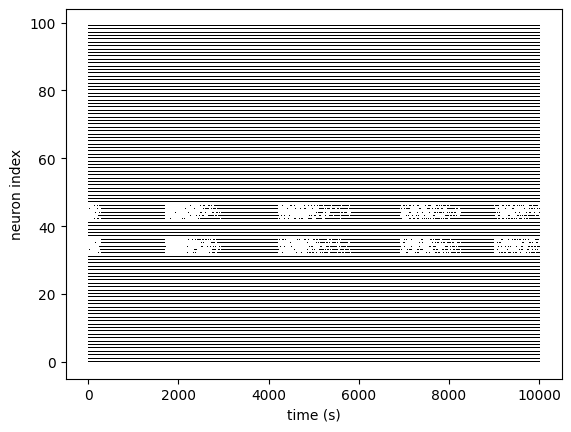

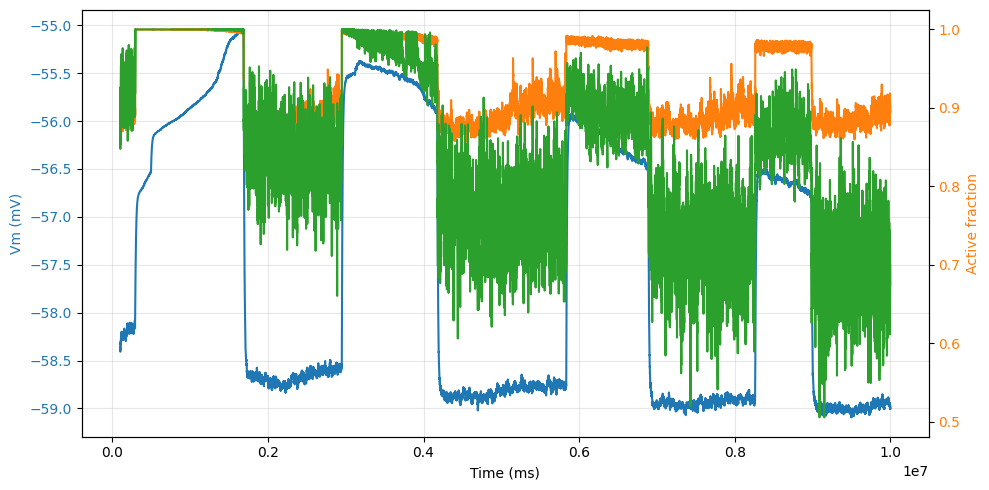

In [16]:
start_scope()
defaultclock.dt = 1000 * us
net = run_sim(tau_ins_AMPA=500*second,
              tau_int_AMPA=5000*second,
              tau_ins_GABA=5000*second,
              tau_int_GABA=500*second,
              show_time=10000*second)


V_mon = net['V_mon']  
act_mon=net['act_mon']
act_mon_I=net['act_mon_I']
spE = net['sp_exc']
spI = net['sp_inh']
plot_raster(spE.i, spE.t, time_unit=second, marker=',', color='k')


fig, ax1 = plt.subplots(figsize=(10,5))

ax1.plot(V_mon.t[500:]/ms, V_mon.vm_pop[0,500:]/mV, color='tab:blue', label='Vm mean')
ax1.set_xlabel('Time (ms)')
ax1.set_ylabel('Vm (mV)', color='tab:blue')
ax1.tick_params(axis='y', labelcolor='tab:blue')
ax1.grid(True, alpha=0.3)

ax2 = ax1.twinx()
ax2.plot(act_mon.t[500:]/ms, act_mon.frac_act[0,500:], color='tab:orange', label='Active fraction')
ax2.plot(act_mon_I.t[500:]/ms, act_mon_I.frac_act[0,500:], color='tab:green', label='Active fraction')
ax2.set_ylabel('Active fraction', color='tab:orange')
ax2.tick_params(axis='y', labelcolor='tab:orange')

fig.tight_layout()
plt.show()

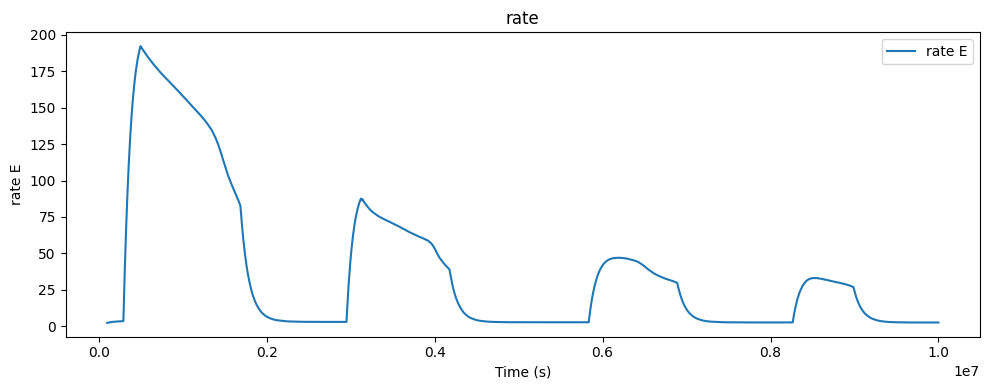

In [17]:
r_est_E = net['rate_pop_mon_E']  
r_est_I = net['rate_pop_mon_I']  

plt.figure(figsize=(10, 4))
plt.plot(r_est_E.t[500:]/ms, r_est_E.r_pop_E[0,500:]/Hz, color='tab:blue', label='rate E')
#plt.plot(r_est_I.t[500:]/ms, r_est_I.r_pop_I[0,500:]/Hz, color='tab:green', label='rate I')
plt.xlabel('Time (s)')
plt.ylabel('rate E')
plt.title('rate')
plt.legend()
plt.tight_layout()